### У нас сохранена матрица в формате npy and csv. Она содержит данные с фазовым сдвигом [0], проводимостью [1], параметрами ширины между кривыми [2] и параметром степени кривизны а [3].

Что нужно сделать, чтобы подготовить эти данные к обработке?
1. Четко указать какой параметр является входящим и что является лейблом для него.
    **Предположение** Вероятно входящими параметрами у нас будут mode_phase and mode_tran. Это будут 2 input. В качестве Y (лейбл) мы можем передавать матрицу с объединенным описанием геометрии ячейки (да, так и сделаем). So, we extract shape feature [2, 3] and accumulate them into seperated matrix 'shape_parameters'. Итого на выходе мы получаем лейбл Y. Таким образом, на основе требований для фазового смещения в конкретной точке пространства мы сможем создавать геометрию без расчета новой ячейки и симмуляции. А просто модель будет предполагать форму ячейки в конкретной точке пространства (на линзе), затем упрощенными 2Д расчетами оценивать FOM этой линзы и дообучаться по результатам.

2. Разделить сгенерированный набор данных на тест и трейн
3. Подобрать базовые гипер-параметры и создать простую полносвязную сеть
4. Создать цикл с предположением, расчетом ошибки, оптимизацией
5. Добавить график обучения модели
6. Сохранить модель

In [58]:
import numpy as np
import torch
from torch import nn

from sklearn.model_selection import train_test_split

In [59]:
loaded_data_npy = np.load('vectors.npy')

In [60]:
type(loaded_data_npy)

numpy.ndarray

In [61]:
loaded_data_npy.shape

(1000, 4)

In [62]:
X_input = loaded_data_npy[:,:1] # mode_phase and mode_tran. В индексе [1] находится прозрачность. Для обучения она нам не нужна - просто не передаем эти индексы и значения в модель.
Y_labels = loaded_data_npy[:,2:] # width and a

In [63]:
print("X:\n", X_input[:10,:])
print("Y:\n", Y_labels[:10,:])

X:
 [[-4.45787766]
 [-4.45692422]
 [-4.45594982]
 [-4.45495376]
 [-4.45393528]
 [-4.45289362]
 [-4.45182795]
 [-4.45073742]
 [-4.44962114]
 [-4.44847817]]
Y:
 [[0.3        0.5       ]
 [0.3017017  0.5025025 ]
 [0.3034034  0.50500501]
 [0.30510511 0.50750751]
 [0.30680681 0.51001001]
 [0.30850851 0.51251251]
 [0.31021021 0.51501502]
 [0.31191191 0.51751752]
 [0.31361361 0.52002002]
 [0.31531532 0.52252252]]


In [64]:
# turn numpy into torch
X_input = torch.from_numpy(X_input).type(torch.float)
Y_labels = torch.from_numpy(Y_labels).type(torch.float)
X_input[:10], Y_labels[:10]

(tensor([[-4.4579],
         [-4.4569],
         [-4.4559],
         [-4.4550],
         [-4.4539],
         [-4.4529],
         [-4.4518],
         [-4.4507],
         [-4.4496],
         [-4.4485]]),
 tensor([[0.3000, 0.5000],
         [0.3017, 0.5025],
         [0.3034, 0.5050],
         [0.3051, 0.5075],
         [0.3068, 0.5100],
         [0.3085, 0.5125],
         [0.3102, 0.5150],
         [0.3119, 0.5175],
         [0.3136, 0.5200],
         [0.3153, 0.5225]]))

In [65]:
X_input.size()

torch.Size([1000, 1])

In [66]:
X_input.shape

torch.Size([1000, 1])

In [67]:
X_input_train, X_input_test, Y_labels_train, Y_labels_test = train_test_split(X_input, Y_labels, test_size=0.2)

In [68]:
len(X_input_train), len(X_input_test), len(Y_labels_train), len(Y_labels_test)

(800, 200, 800, 200)

In [69]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [70]:
#1. Let's creat the model using nn.Sequential()
model_shape_prediction = nn.Sequential(
    nn.Linear(in_features=1, out_features=16, bias=False), 
    nn.ReLU(),
    nn.Tanh(),
    nn.ReLU(),
    nn.Linear(in_features=16, out_features=2)
).to(device)

In [71]:
model_shape_prediction

Sequential(
  (0): Linear(in_features=1, out_features=16, bias=False)
  (1): ReLU()
  (2): Tanh()
  (3): ReLU()
  (4): Linear(in_features=16, out_features=2, bias=True)
)

In [72]:
loss_fn = nn.L1Loss()

In [73]:
optimizer = torch.optim.Adam(
    params=model_shape_prediction.parameters(),
    lr=0.001
)

Epoch: 0 | Loss: 1.09986, Test_loss: 1.15591
Epoch: 500 | Loss: 0.51661, Test_loss: 0.50148
Epoch: 1000 | Loss: 0.46542, Test_loss: 0.45148
Epoch: 1500 | Loss: 0.39875, Test_loss: 0.38745
Epoch: 2000 | Loss: 0.33722, Test_loss: 0.32847
Epoch: 2500 | Loss: 0.30279, Test_loss: 0.29593
Epoch: 3000 | Loss: 0.27176, Test_loss: 0.26684
Epoch: 3500 | Loss: 0.23793, Test_loss: 0.23405
Epoch: 4000 | Loss: 0.20006, Test_loss: 0.19745
Epoch: 4500 | Loss: 0.15869, Test_loss: 0.15770
Epoch: 5000 | Loss: 0.11548, Test_loss: 0.11659
Epoch: 5500 | Loss: 0.08842, Test_loss: 0.09081
Epoch: 6000 | Loss: 0.07896, Test_loss: 0.08293
Epoch: 6500 | Loss: 0.07580, Test_loss: 0.08111
Epoch: 7000 | Loss: 0.07496, Test_loss: 0.08067
Epoch: 7500 | Loss: 0.07485, Test_loss: 0.08040
Epoch: 8000 | Loss: 0.07480, Test_loss: 0.08063
Epoch: 8500 | Loss: 0.07482, Test_loss: 0.08058
Epoch: 9000 | Loss: 0.07482, Test_loss: 0.08111
Epoch: 9500 | Loss: 0.07483, Test_loss: 0.08076


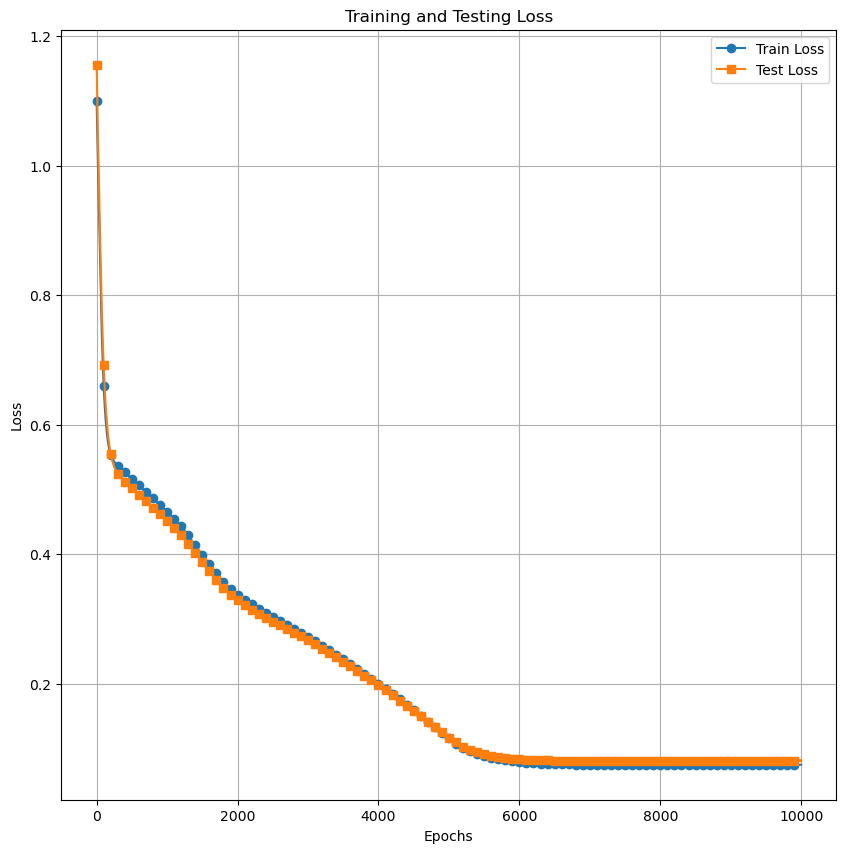

In [74]:
import matplotlib.pyplot as plt

epochs = 10000

# Put data to target device
X_input_train, Y_labels_train = X_input_train.to(device), Y_labels_train.to(device)
X_input_test, Y_labels_test = X_input_test.to(device), Y_labels_test.to(device)

# Списки для сохранения значений потерь
train_losses = []
test_losses = []

for epoch in range(epochs):
    #### Training
    model_shape_prediction.train()

    # 1. Forward pass
    Y_labels_pred = model_shape_prediction(X_input_train)
    
    # 2. Calculate loss
    loss = loss_fn(Y_labels_pred, Y_labels_train)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backward (backpropagation)
    loss.backward()

    # 5. Optimizer step (gradient descent)
    optimizer.step()

    ### Testing
    model_shape_prediction.eval()
    with torch.inference_mode():
        # 1. Forward pass
        test_pred = model_shape_prediction(X_input_test)
        # 2. Calculate test loss
        test_loss = loss_fn(test_pred, Y_labels_test)

    # Сохранение значений потерь
    train_losses.append(loss.item())
    test_losses.append(test_loss.item())

    # Print out what's happening
    if epoch % 500 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Test_loss: {test_loss:.5f}")

# Построение графика после завершения обучения
plt.figure(figsize=(10, 10))
plt.plot(range(epochs), train_losses, label='Train Loss', marker='o', markevery=100)
plt.plot(range(epochs), test_losses, label='Test Loss', marker='s', markevery=100)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Testing Loss')
plt.legend()
plt.grid(True)
plt.show()


In [75]:
torch.save(model_shape_prediction, "model_shape_prediction.pth")

In [76]:
loaded_model = torch.load("model_shape_prediction.pth")

/tmp/ipykernel_2627/3545288890.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_model = torch.load("model_shape_prediction.pth")


In [83]:
X_new_data = torch.tensor([-3.0])
X_new_data = X_new_data.to(torch.float32)  # Приводим к типу float32 (если нужно)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_new_data = X_new_data.to(device)
loaded_model = loaded_model.to(device)
X_new_data.shape

torch.Size([3])

In [84]:
X_new_data.ndim

1

In [85]:
# Устанавливаем режим оценки
loaded_model.eval()

Sequential(
  (0): Linear(in_features=1, out_features=16, bias=False)
  (1): ReLU()
  (2): Tanh()
  (3): ReLU()
  (4): Linear(in_features=16, out_features=2, bias=True)
)

In [89]:
# Прогнозирование
with torch.no_grad():
    for i in range(X_new_data.shape[0]):
        data_for_pred = X_new_data[i]
        prediction = loaded_model(data_for_pred)
    
# Вывод
print("Выходные данные модели:", prediction)

print(prediction.shape)
print(prediction.size())
print(type(prediction[0]))


RuntimeError: both arguments to linear need to be at least 1D, but they are 0D and 2D

**Note**

Мы реализовали заполнение всего пространства форм и геометрий без разрывов. В примере кода на котором я базируюсь этот момент реализуется на основе интерполяции:

gdc = np.linspace(0.1, 0.9, 30)  # grating duty cycle
mode_tran = np.empty(gdc.size)
mode_phase = np.empty(gdc.size)
for n in range(gdc.size):
    mode_tran[n], mode_phase[n] = grating(gp, gh, [gdc[n]])

gdc_new = np.linspace(0.16, 0.65, 500)
mode_phase_interp = np.interp(gdc_new, gdc, mode_phase)
print(f"phase-range:, {mode_phase_interp.max() - mode_phase_interp.min():.6f}")